In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import classification_report

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42)

train_set = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, num_workers=2)

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# 28x28 zurgiig 112x112 bolgood 3 suvagtai bolgono
def prep(x):
    x = F.interpolate(x.to(device), size=112, mode="bilinear").repeat(1, 3, 1, 1)
    return (x - mean) / std

In [ ]:
model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
# suuliin davhargiig 10 angitai bolgoj solino
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 10)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

In [3]:
# 2 epoch finetune
for epoch in range(2):
    model.train()
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(prep(x)), y.to(device))
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1} | loss {loss.item():.4f}")

epoch 1 | loss 0.0701


epoch 2 | loss 0.0065


In [ ]:
# test deer shalgah
model.eval()
preds, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds.append(model(prep(x)).argmax(1).cpu())
        labels.append(y)
preds, labels = torch.cat(preds), torch.cat(labels)

print(f"accuracy: {(preds == labels).float().mean():.4f}")
print(classification_report(labels, preds, digits=4))

Тестийн нарийвчлал: 0.9926
              precision    recall  f1-score   support

           0     0.9888    0.9908    0.9898       980
           1     0.9956    0.9982    0.9969      1135
           2     0.9904    0.9971    0.9937      1032
           3     0.9960    0.9960    0.9960      1010
           4     0.9959    0.9888    0.9923       982
           5     0.9911    0.9955    0.9933       892
           6     0.9906    0.9927    0.9917       958
           7     0.9961    0.9932    0.9946      1028
           8     0.9908    0.9990    0.9949       974
           9     0.9899    0.9742    0.9820      1009

    accuracy                         0.9926     10000
   macro avg     0.9925    0.9926    0.9925     10000
weighted avg     0.9926    0.9926    0.9926     10000



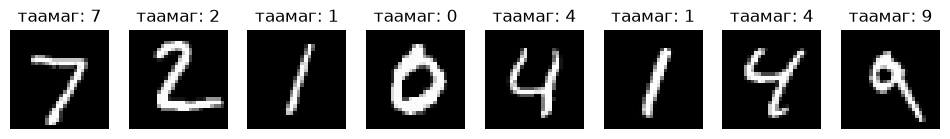

In [5]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(test_set.data[i], cmap="gray")
    ax.set_title(f"таамаг: {preds[i].item()}")
    ax.axis("off")
plt.show()